### Lab 6 — Association Rule Mining with Apriori and FP-Growth

**Name:** _Aditya Rayarapu_  
**Course:** MSCS 634 — Advanced Big Data and Data Mining  
**Assignment:** Lab 6: Association Rule Mining with Apriori and FP-Growth  
**Dataset:** UCI Online Retail (Invoice-level product transactions)

### Learning objectives
1. Prepare transaction-level data and construct a Boolean, one-hot basket matrix.
2. Visualize popular products and product co-occurrence using Seaborn.
3. Mine frequent itemsets using **Apriori** and **FP-Growth**, with identical inputs.
4. Generate and interpret association rules using **support, confidence, and lift**.
5. Compare the algorithms' frequent itemsets, execution time, and practical trade-offs.

**Execution instructions:** Run all cells from top to bottom after installing the packages in `requirements.txt`. The first full run downloads the dataset from UCI and caches it locally. All charts are saved to `screenshots/`, and comparison tables are exported to `outputs/`.

### Step 0 — Environment and configuration

**Reproducibility:** All selection and sampling are deterministic (`RANDOM_STATE=42`). A bounded, randomized invoice sample and the most common product descriptions keep Apriori practical on a typical laptop. Both algorithms analyze **exactly the same basket matrix**, so the comparison is fair **within this sampled, filtered dataset**.

If too few itemsets or rules are found, lower `MIN_SUPPORT` or `MIN_CONFIDENCE` and rerun the notebook. If memory use is high, reduce `MAX_TRANSACTIONS` or `TOP_N_ITEMS`. Avoid changing parameters for only one algorithm.

In [26]:
%pip install mlxtend

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/pty.py:66: DeprecationWarning: This process (pid=85297) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [27]:
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

print("mlxtend imported successfully!")

mlxtend imported successfully!


In [28]:
%pip install openpyxl

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/pty.py:66: DeprecationWarning: This process (pid=85297) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [29]:
import pandas as pd

df = pd.read_excel("data/Online Retail.xlsx", engine="openpyxl")

print("Dataset loaded successfully!")
print(df.shape)
display(df.head())

Dataset loaded successfully!
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [30]:
%pip install pandas numpy matplotlib seaborn requests mlxtend openpyxl

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/pty.py:66: DeprecationWarning: This process (pid=85297) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [31]:
# For a brand-new Jupyter/Colab environment, uncomment and run once:
# %pip install -r requirements.txt

import io
import json
import platform
import shutil
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

DATA_DIR = Path('data')
CHART_DIR = Path('screenshots')
OUTPUT_DIR = Path('outputs')
for directory in (DATA_DIR, CHART_DIR, OUTPUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

UCI_DATASET_PAGE = 'https://archive.ics.uci.edu/dataset/352/online+retail'
UCI_DATASET_ZIP = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
EXCEL_PATH = DATA_DIR / 'Online Retail.xlsx'

RANDOM_STATE = 42
COUNTRY = 'United Kingdom'
MAX_TRANSACTIONS = 6000    # Set to None to include every available invoice
TOP_N_ITEMS = 65          # Top items by unique-invoice frequency
MIN_SUPPORT = 0.015       # Itemsets occur in at least 1.5% of retained baskets
MIN_CONFIDENCE = 0.35    # Rules have at least 35% confidence
MIN_LIFT = 1.20          # For a 'strong-rule' interpretation filter
MAX_ITEMSET_LENGTH = 3  # Same maximum length for both algorithms
BENCHMARK_REPEATS = 3
TOP_N_PLOT = 15

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160})


def save_chart(filename):
    """Save the active figure, then show and close it."""
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()


def format_itemset(items):
    """Render a frozenset deterministically for reports and charts."""
    return ' + '.join(sorted(map(str, items)))


print(f'Python: {platform.python_version()} | pandas: {pd.__version__}')
print('Dataset source:', UCI_DATASET_PAGE)
print('Charts will be saved to:', CHART_DIR.resolve())

Python: 3.14.6 | pandas: 3.0.5
Dataset source: https://archive.ics.uci.edu/dataset/352/online+retail
Charts will be saved to: /Users/adityarayarapu/Downloads/MSCS_634_Lab_6/screenshots


### Step 1 — Data preparation

### 1.1 Download and inspect the original dataset

The [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail) contains invoice-level transactions from a UK-based online retailer, with fields such as `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, and `Country`. We access its **official compressed archive** by URL, extracting the included Excel workbook on the first run. This lab does not require shipping the raw 20+ MB dataset with the GitHub submission.

In [32]:
def load_online_retail(path=EXCEL_PATH, url=UCI_DATASET_ZIP):
    if not path.exists():
        print('Downloading the UCI Online Retail archive (first run only)...')
        try:
            response = requests.get(url, timeout=180)
            response.raise_for_status()
            with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
                excel_members = [n for n in archive.namelist()
                                 if n.lower().endswith('.xlsx') and not n.startswith('__MACOSX')]
                if not excel_members:
                    raise ValueError('No .xlsx workbook found in downloaded archive.')
                with archive.open(excel_members[0]) as source, path.open('wb') as target:
                    shutil.copyfileobj(source, target)
        except Exception as exc:
            if path.exists():
                path.unlink()
            raise RuntimeError(
                f'Automatic download failed: {exc}. Download the archive manually from '
                f'{UCI_DATASET_PAGE}, then save the Excel workbook as {path}.'
            ) from exc
        print(f'Cached workbook at {path}')
    return pd.read_excel(path, engine='openpyxl')


raw_df = load_online_retail()
required_columns = {'InvoiceNo', 'Description', 'StockCode', 'Quantity', 'UnitPrice', 'Country'}
missing_columns = required_columns.difference(raw_df.columns)
if missing_columns:
    raise ValueError(f'Unexpected dataset schema. Missing: {missing_columns}')

print(f'Original shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns')
display(raw_df.head(8))
print('Missing values by column:')
display(raw_df.isna().sum().rename('missing_rows').to_frame())

Original shape: 541,909 rows × 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom


Missing values by column:


,missing_rows
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


### 1.2 Clean invalid records

**Cleaning decisions** (applied before sampling):

- Remove duplicate rows and records with missing invoice ID, stock code, or product description.
- Exclude canceled/credit invoices (`InvoiceNo` beginning with `C`), non-positive quantities, and non-positive prices.
- Normalize descriptions (trim spaces, uppercase) so that minor formatting differences do not create separate items.
- Remove a small, explicit set of non-product charges (such as postage and bank charges).
- Limit this analysis to **United Kingdom** invoices to avoid conflating potentially different international purchasing patterns.

Association mining uses **presence of products per invoice**, not purchased quantities; duplicate product lines in a single invoice count only once.

In [33]:
def clean_transactions(frame):
    data = frame.drop_duplicates().dropna(
        subset=['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'Country']
    ).copy()
    data['InvoiceNo'] = data['InvoiceNo'].astype(str).str.strip()
    data['Description'] = data['Description'].astype(str).str.upper().str.strip()
    data['Country'] = data['Country'].astype(str).str.strip()
    data['Quantity'] = pd.to_numeric(data['Quantity'], errors='coerce')
    data['UnitPrice'] = pd.to_numeric(data['UnitPrice'], errors='coerce')
    data = data[
        (~data['InvoiceNo'].str.upper().str.startswith('C'))
        & (data['Quantity'] > 0)
        & (data['UnitPrice'] > 0)
        & (data['Description'] != '')
        & (data['Country'] == COUNTRY)
    ].copy()
    non_products = {
        'POSTAGE', 'DOTCOM POSTAGE', 'CARRIAGE', 'BANK CHARGES',
        'MANUAL', 'AMAZON FEE', 'DISCOUNT', 'ADJUST BAD DEBT'
    }
    data = data[~data['Description'].isin(non_products)].copy()
    return data


clean_df = clean_transactions(raw_df)
clean_df = clean_df.sort_values(['InvoiceNo', 'Description']).reset_index(drop=True)
print(f'Original line items: {len(raw_df):,}')
print(f'Cleaned line items (UK, valid sales): {len(clean_df):,}')
print(f'Available unique invoices: {clean_df["InvoiceNo"].nunique():,}')
print(f'Available unique products: {clean_df["Description"].nunique():,}')
if clean_df.empty:
    raise ValueError('No valid transactions left after cleaning. Check the configuration.')
display(clean_df.head())

Original line items: 541,909
Cleaned line items (UK, valid sales): 478,907
Available unique invoices: 17,903
Available unique products: 3,989


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
1,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
2,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
3,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom


### 1.3 Build the transaction–item matrix

1. Deduplicate invoice-product combinations (presence/absence).
2. Select up to `MAX_TRANSACTIONS` distinct invoices, using a fixed random seed.
3. Select the `TOP_N_ITEMS` most commonly purchased descriptions **within that invoice sample**.
4. Build a Boolean basket: rows are invoices and columns are products.

**Important denominator:** Some sampled invoices contain none of the retained top products. Those rows are discarded. Thus, all subsequent support values are calculated over the **retained invoices with at least one of the selected products**. Findings are exploratory and should not be generalized to all UCI invoices without rerunning with broader coverage.

In [34]:
invoice_products = clean_df[['InvoiceNo', 'Description']].drop_duplicates()
all_invoice_ids = invoice_products['InvoiceNo'].unique()
rng = np.random.default_rng(RANDOM_STATE)

if MAX_TRANSACTIONS is not None and len(all_invoice_ids) > MAX_TRANSACTIONS:
    chosen_invoice_ids = rng.choice(all_invoice_ids, size=MAX_TRANSACTIONS, replace=False)
else:
    chosen_invoice_ids = all_invoice_ids

sampled_lines = invoice_products[invoice_products['InvoiceNo'].isin(chosen_invoice_ids)].copy()
product_frequency = sampled_lines['Description'].value_counts()
selected_items = product_frequency.head(TOP_N_ITEMS).index
selected_lines = sampled_lines[sampled_lines['Description'].isin(selected_items)].copy()
selected_lines['present'] = True

basket = selected_lines.pivot_table(
    index='InvoiceNo', columns='Description', values='present',
    aggfunc='max', fill_value=False
).astype(bool).sort_index().sort_index(axis=1)

if basket.empty:
    raise ValueError('Basket is empty; consider adjusting COUNTRY or TOP_N_ITEMS.')
assert basket.to_numpy().dtype == np.bool_, 'Apriori/FP-Growth expect a Boolean one-hot matrix.'

print(f'Sampled invoices before top-item filtering: {len(chosen_invoice_ids):,}')
print(f'Invoices retained in Boolean basket: {len(basket):,}')
print(f'Number of product columns: {basket.shape[1]}')
print(f'Basket density: {basket.to_numpy().mean():.2%}')
display(basket.head(8).astype(int))

Sampled invoices before top-item filtering: 6,000
Invoices retained in Boolean basket: 4,518
Number of product columns: 65
Basket density: 7.40%


Description,6 RIBBONS RUSTIC CHARM,60 TEATIME FAIRY CAKE CASES,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,ASSORTED COLOUR BIRD ORNAMENT,BAKING SET 9 PIECE RETROSPOT,CHARLOTTE BAG SUKI DESIGN,CHOCOLATE HOT WATER BOTTLE,DOLLY GIRL LUNCH BOX,GARDENERS KNEELING PAD CUP OF TEA,...,SET OF 6 SPICE TINS PANTRY DESIGN,SET/20 RED RETROSPOT PAPER NAPKINS,SET/5 RED RETROSPOT LID GLASS BOWLS,SPACEBOY LUNCH BOX,SPOTTY BUNTING,VICTORIAN GLASS HANGING T-LIGHT,VINTAGE SNAP CARDS,WHITE HANGING HEART T-LIGHT HOLDER,WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
536378,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536384,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536388,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536395,0,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536396,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
536404,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536415,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


### 1.4 Exploratory visualizations (Seaborn)

The bar chart shows **invoice frequency** rather than quantity sold. The heatmap shows the count of retained invoices containing each product pair. Diagonal cells show the number of invoices containing each individual product.

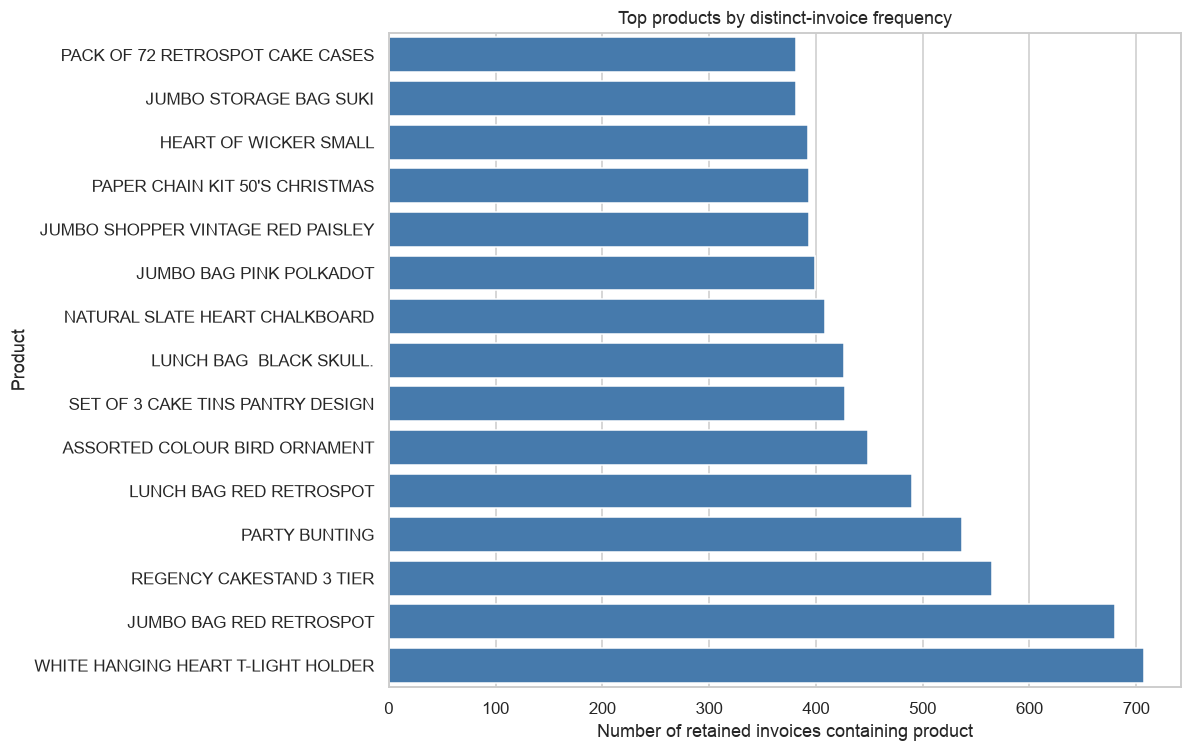

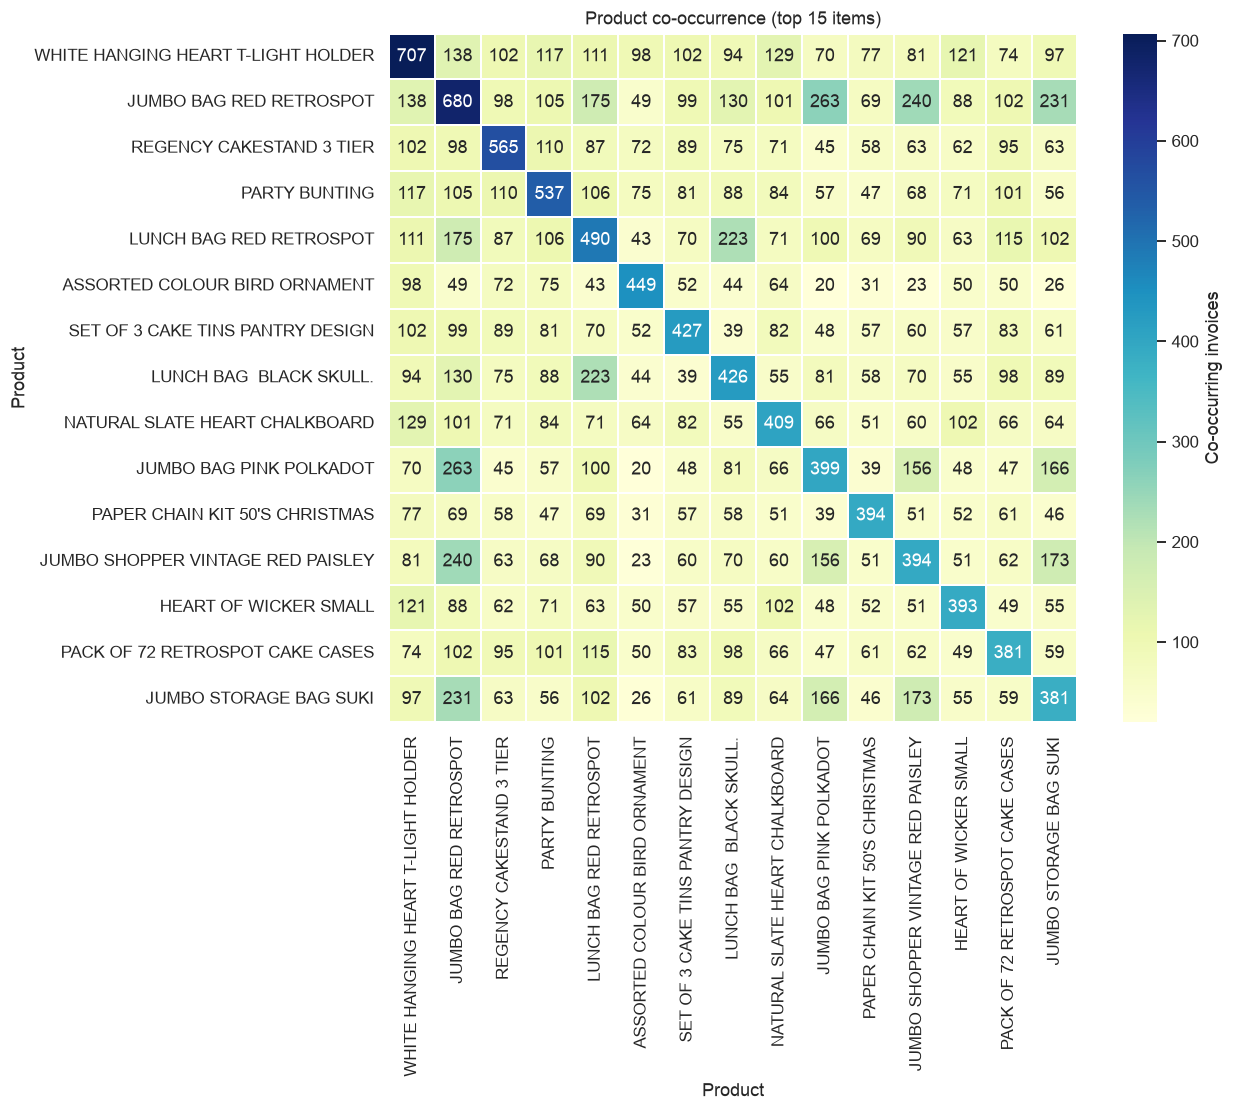

Most frequently occurring product: WHITE HANGING HEART T-LIGHT HOLDER (707 invoices, support=15.65%)


In [35]:
item_counts = basket.sum(axis=0).sort_values(ascending=False)
top_items = item_counts.head(TOP_N_PLOT).sort_values(ascending=True)
item_plot = pd.DataFrame({'item': top_items.index, 'invoice_count': top_items.values})

plt.figure(figsize=(11, 7))
sns.barplot(data=item_plot, x='invoice_count', y='item', color='#357ABD')
plt.title('Top products by distinct-invoice frequency')
plt.xlabel('Number of retained invoices containing product')
plt.ylabel('Product')
save_chart('01_top_items.png')

heatmap_items = item_counts.head(15).index.tolist()
co_matrix = basket[heatmap_items].astype(np.int32).T.dot(basket[heatmap_items].astype(np.int32))
plt.figure(figsize=(12, 10))
sns.heatmap(co_matrix, cmap='YlGnBu', annot=True, fmt='d', square=True,
            linewidths=0.25, cbar_kws={'label': 'Co-occurring invoices'})
plt.title('Product co-occurrence (top 15 items)')
plt.xlabel('Product')
plt.ylabel('Product')
save_chart('02_item_cooccurrence_heatmap.png')

print('Most frequently occurring product:', item_counts.index[0],
      f'({int(item_counts.iloc[0]):,} invoices, support={item_counts.iloc[0]/len(basket):.2%})')

### Step 2 — Frequent itemset mining with Apriori

**Apriori principle:** Every nonempty subset of a frequent itemset must also be frequent. Apriori generates candidate itemsets and prunes candidates with infrequent subsets.

**Support** for an itemset `X` is:

\[\operatorname{support}(X)=\frac{\#\text{invoices containing }X}{\#\text{retained invoices}}\]

The notebook times repeated runs with `time.perf_counter()`. The median gives a simple, reproducible performance estimate, but timings still depend on machine load and environment.

In [36]:
def benchmark_miner(miner, basket_frame, repeats=BENCHMARK_REPEATS, **kwargs):
    elapsed_times = []
    result = None
    for _ in range(repeats):
        start = time.perf_counter()
        result = miner(basket_frame, **kwargs)
        elapsed_times.append(time.perf_counter() - start)
    result = result.copy()
    result['length'] = result['itemsets'].map(len)
    result['itemset_label'] = result['itemsets'].map(format_itemset)
    result = result.sort_values(['support', 'length', 'itemset_label'],
                                ascending=[False, True, True]).reset_index(drop=True)
    return result, elapsed_times


apriori_itemsets, apriori_times = benchmark_miner(
    apriori,
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_ITEMSET_LENGTH
)

print('Apriori:')
print('  Frequent itemsets:', len(apriori_itemsets))
print('  Median execution time:', f'{np.median(apriori_times):.4f} seconds')
print('  Repeated measurements:', [round(t, 4) for t in apriori_times])
display(apriori_itemsets[['support', 'itemsets', 'length']].head(20))

if apriori_itemsets.empty:
    raise ValueError('Apriori found no itemsets. Lower MIN_SUPPORT and rerun.')

Apriori:
  Frequent itemsets: 489
  Median execution time: 0.0323 seconds
  Repeated measurements: [0.0329, 0.0323, 0.032]


,support,itemsets,length
0,0.156485,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
1,0.150509,frozenset({JUMBO BAG RED RETROSPOT}),1
2,0.125055,frozenset({REGENCY CAKESTAND 3 TIER}),1
3,0.118858,frozenset({PARTY BUNTING}),1
4,0.108455,frozenset({LUNCH BAG RED RETROSPOT}),1
5,0.099380,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
6,0.094511,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
7,0.094290,frozenset({LUNCH BAG BLACK SKULL.}),1
8,0.090527,frozenset({NATURAL SLATE HEART CHALKBOARD}),1
9,0.088313,frozenset({JUMBO BAG PINK POLKADOT}),1


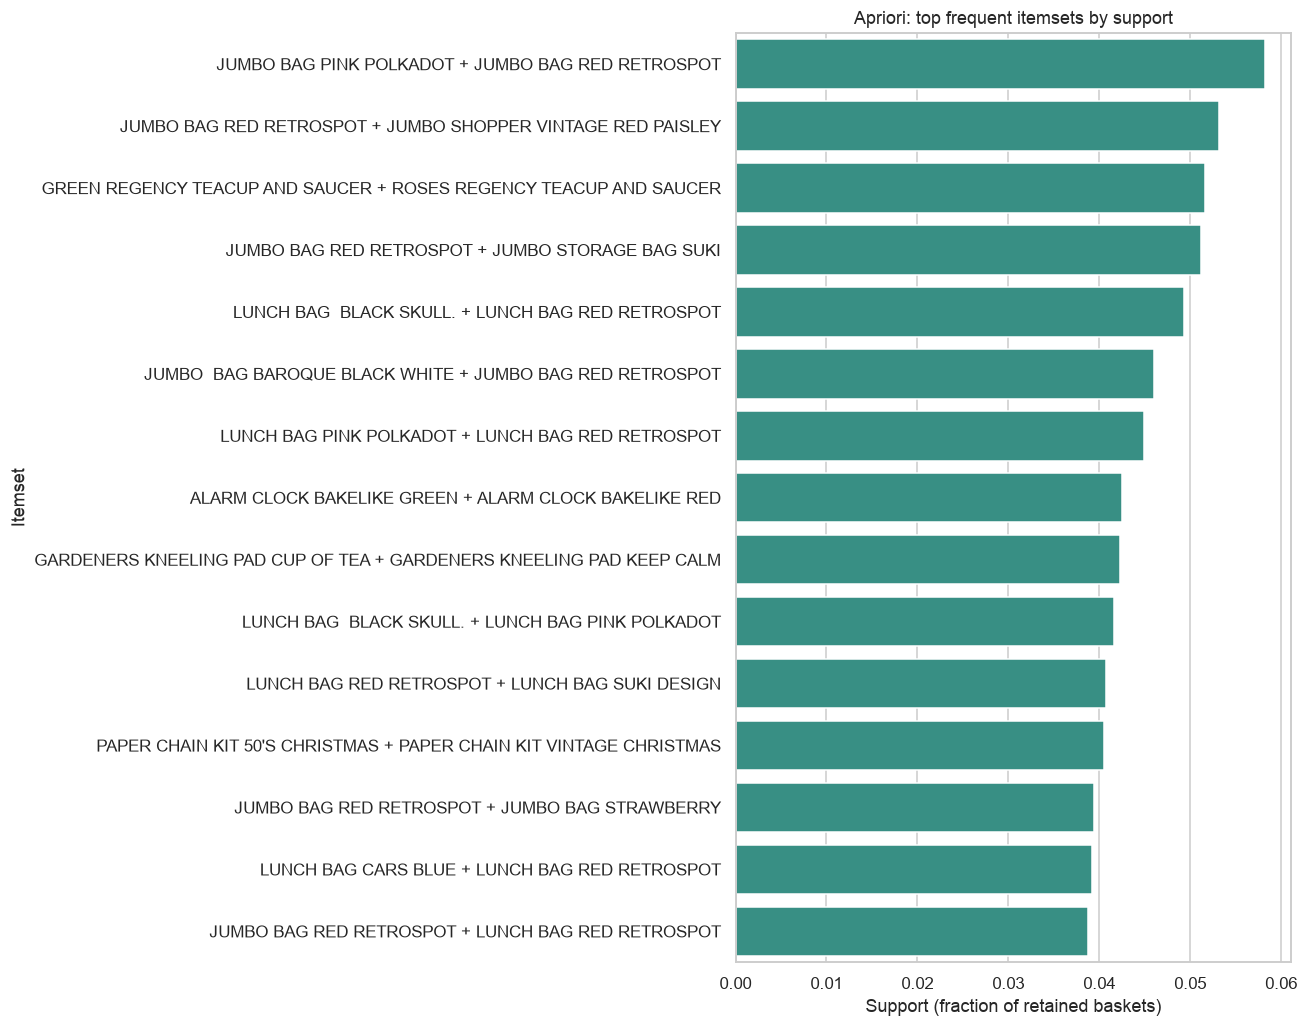

In [37]:
# Visualize top multi-item sets where available; otherwise show single-item sets.
apriori_multi = apriori_itemsets[apriori_itemsets['length'] >= 2]
apriori_to_plot = (apriori_multi if not apriori_multi.empty else apriori_itemsets).head(TOP_N_PLOT)
plt.figure(figsize=(12, max(5, 0.5 * len(apriori_to_plot) + 2)))
sns.barplot(data=apriori_to_plot, x='support', y='itemset_label', color='#2A9D8F')
plt.title('Apriori: top frequent itemsets by support')
plt.xlabel('Support (fraction of retained baskets)')
plt.ylabel('Itemset')
save_chart('03_apriori_itemsets.png')

apriori_itemsets[['support', 'itemset_label', 'length']].to_csv(
    OUTPUT_DIR / 'apriori_frequent_itemsets.csv', index=False
)

### Step 3 — Frequent itemset mining with FP-Growth

**FP-Growth principle:** An FP-tree compresses shared transaction prefixes and recursively mines conditional pattern bases without explicitly generating Apriori-style candidate sets.

For valid comparisons, the same `basket`, `MIN_SUPPORT`, `MAX_ITEMSET_LENGTH`, and number of benchmark repeats are used for both algorithms.

In [38]:
fpgrowth_itemsets, fpgrowth_times = benchmark_miner(
    fpgrowth,
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_ITEMSET_LENGTH
)

print('FP-Growth:')
print('  Frequent itemsets:', len(fpgrowth_itemsets))
print('  Median execution time:', f'{np.median(fpgrowth_times):.4f} seconds')
print('  Repeated measurements:', [round(t, 4) for t in fpgrowth_times])
display(fpgrowth_itemsets[['support', 'itemsets', 'length']].head(20))

if fpgrowth_itemsets.empty:
    raise ValueError('FP-Growth found no itemsets. Lower MIN_SUPPORT and rerun.')

FP-Growth:
  Frequent itemsets: 489
  Median execution time: 0.0403 seconds
  Repeated measurements: [0.0417, 0.0398, 0.0403]


,support,itemsets,length
0,0.156485,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
1,0.150509,frozenset({JUMBO BAG RED RETROSPOT}),1
2,0.125055,frozenset({REGENCY CAKESTAND 3 TIER}),1
3,0.118858,frozenset({PARTY BUNTING}),1
4,0.108455,frozenset({LUNCH BAG RED RETROSPOT}),1
5,0.099380,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
6,0.094511,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
7,0.094290,frozenset({LUNCH BAG BLACK SKULL.}),1
8,0.090527,frozenset({NATURAL SLATE HEART CHALKBOARD}),1
9,0.088313,frozenset({JUMBO BAG PINK POLKADOT}),1


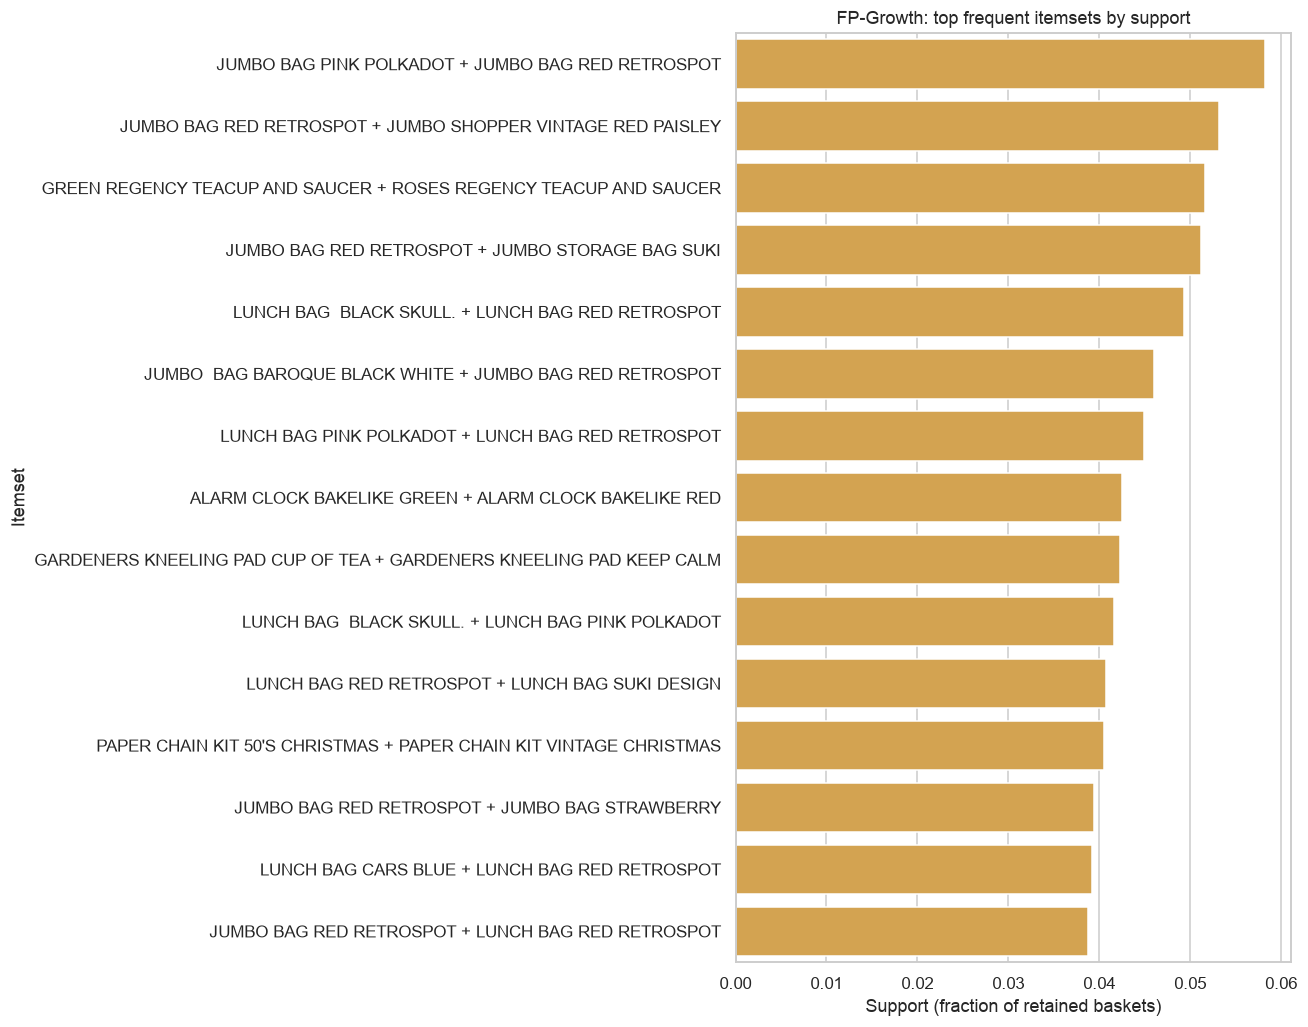

In [39]:
fpgrowth_multi = fpgrowth_itemsets[fpgrowth_itemsets['length'] >= 2]
fpgrowth_to_plot = (fpgrowth_multi if not fpgrowth_multi.empty else fpgrowth_itemsets).head(TOP_N_PLOT)
plt.figure(figsize=(12, max(5, 0.5 * len(fpgrowth_to_plot) + 2)))
sns.barplot(data=fpgrowth_to_plot, x='support', y='itemset_label', color='#E9A83B')
plt.title('FP-Growth: top frequent itemsets by support')
plt.xlabel('Support (fraction of retained baskets)')
plt.ylabel('Itemset')
save_chart('04_fpgrowth_itemsets.png')

fpgrowth_itemsets[['support', 'itemset_label', 'length']].to_csv(
    OUTPUT_DIR / 'fpgrowth_frequent_itemsets.csv', index=False
)

### Step 4 — Association rule generation and analysis

A rule `A → B` says invoices containing `A` also tend to contain `B`.

- **Support(A → B)** = P(A ∩ B). A rule must occur sufficiently often to be relevant.
- **Confidence(A → B)** = P(B | A) = support(A ∪ B) / support(A). This is the fraction of baskets with `A` that also have `B`.
- **Lift(A → B)** = confidence(A → B) / support(B). Lift > 1 indicates positive association relative to independence; lift = 1 indicates no departure from independence; lift < 1 indicates negative association.

**Key caution:** Association does **not** establish causation. A high lift from a very low-support itemset can be unstable, so inspect support alongside confidence and lift.

In [40]:
def build_rules(itemsets, basket_size, min_confidence=MIN_CONFIDENCE):
    if not (itemsets['length'] >= 2).any():
        return pd.DataFrame(columns=['antecedents', 'consequents', 'support', 'confidence', 'lift'])
    rules = association_rules(
        itemsets[['support', 'itemsets']],
        num_itemsets=basket_size,
        metric='confidence',
        min_threshold=min_confidence
    )
    if rules.empty:
        return rules
    rules = rules.sort_values(['lift', 'confidence', 'support'],
                              ascending=False).reset_index(drop=True)
    rules['antecedent_label'] = rules['antecedents'].map(format_itemset)
    rules['consequent_label'] = rules['consequents'].map(format_itemset)
    return rules


apriori_rules = build_rules(apriori_itemsets, len(basket))
fpgrowth_rules = build_rules(fpgrowth_itemsets, len(basket))

print(f'Apriori-derived rules (confidence >= {MIN_CONFIDENCE:.0%}): {len(apriori_rules)}')
print(f'FP-Growth-derived rules (confidence >= {MIN_CONFIDENCE:.0%}): {len(fpgrowth_rules)}')

rule_columns = ['antecedent_label', 'consequent_label', 'support', 'confidence', 'lift']
for algorithm, rules in [('Apriori', apriori_rules), ('FP-Growth', fpgrowth_rules)]:
    print(f'\nTop association rules from {algorithm}:')
    display(rules[rule_columns].head(15) if not rules.empty else
            pd.DataFrame(columns=rule_columns))
    if not rules.empty:
        rules[rule_columns].to_csv(
            OUTPUT_DIR / f'{algorithm.lower().replace("-", "")}_association_rules.csv',
            index=False
        )

Apriori-derived rules (confidence >= 35%): 451
FP-Growth-derived rules (confidence >= 35%): 451

Top association rules from Apriori:


,antecedent_label,consequent_label,support,confidence,lift
0,GREEN REGENCY TEACUP AND SAUCER,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU...,0.028110,0.403175,11.676557
1,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU...,GREEN REGENCY TEACUP AND SAUCER,0.028110,0.814103,11.676557
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,0.028110,0.409677,11.568266
3,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,ROSES REGENCY TEACUP AND SAUCER,0.028110,0.793750,11.568266
4,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.033643,0.612903,10.901956
5,SPACEBOY LUNCH BOX,DOLLY GIRL LUNCH BOX,0.033643,0.598425,10.901956
6,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.051571,0.739683,10.780276
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.051571,0.751613,10.780276
8,CHARLOTTE BAG SUKI DESIGN + LUNCH BAG RED RETR...,RED RETROSPOT CHARLOTTE BAG,0.018150,0.700855,10.733768
9,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.042275,0.754941,10.692232



Top association rules from FP-Growth:


,antecedent_label,consequent_label,support,confidence,lift
0,GREEN REGENCY TEACUP AND SAUCER,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU...,0.028110,0.403175,11.676557
1,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU...,GREEN REGENCY TEACUP AND SAUCER,0.028110,0.814103,11.676557
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,0.028110,0.409677,11.568266
3,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,ROSES REGENCY TEACUP AND SAUCER,0.028110,0.793750,11.568266
4,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.033643,0.612903,10.901956
5,SPACEBOY LUNCH BOX,DOLLY GIRL LUNCH BOX,0.033643,0.598425,10.901956
6,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.051571,0.739683,10.780276
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.051571,0.751613,10.780276
8,CHARLOTTE BAG SUKI DESIGN + LUNCH BAG RED RETR...,RED RETROSPOT CHARLOTTE BAG,0.018150,0.700855,10.733768
9,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.042275,0.754941,10.692232


In [41]:
# Analyze strongest Apriori rules (the algorithms should identify the same rule set).
if apriori_rules.empty:
    print('No rules meet the confidence threshold; try lowering MIN_CONFIDENCE.')
else:
    strong_rules = apriori_rules[apriori_rules['lift'] >= MIN_LIFT].copy()
    print(f'Strong rules meeting lift >= {MIN_LIFT:.2f}: {len(strong_rules):,}')
    display(strong_rules[rule_columns].head(10))

    chosen = (strong_rules if not strong_rules.empty else apriori_rules).iloc[0]
    print('\nExample rule interpretation:')
    print(f'  {chosen["antecedent_label"]}  ->  {chosen["consequent_label"]}')
    print(f'  Support: {chosen["support"]:.2%} of retained invoices contain both sides.')
    print(f'  Confidence: {chosen["confidence"]:.2%} of invoices with the antecedent also contain the consequent.')
    print(f'  Lift: {chosen["lift"]:.2f}x the baseline probability of the consequent.')
    print('  Interpretation: this is an association, not evidence of causation.')

Strong rules meeting lift >= 1.20: 451


,antecedent_label,consequent_label,support,confidence,lift
0,GREEN REGENCY TEACUP AND SAUCER,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU...,0.028110,0.403175,11.676557
1,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU...,GREEN REGENCY TEACUP AND SAUCER,0.028110,0.814103,11.676557
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,0.028110,0.409677,11.568266
3,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,ROSES REGENCY TEACUP AND SAUCER,0.028110,0.793750,11.568266
4,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.033643,0.612903,10.901956
5,SPACEBOY LUNCH BOX,DOLLY GIRL LUNCH BOX,0.033643,0.598425,10.901956
6,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.051571,0.739683,10.780276
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.051571,0.751613,10.780276
8,CHARLOTTE BAG SUKI DESIGN + LUNCH BAG RED RETR...,RED RETROSPOT CHARLOTTE BAG,0.018150,0.700855,10.733768
9,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.042275,0.754941,10.692232



Example rule interpretation:
  GREEN REGENCY TEACUP AND SAUCER  ->  REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACUP AND SAUCER
  Support: 2.81% of retained invoices contain both sides.
  Confidence: 40.32% of invoices with the antecedent also contain the consequent.
  Lift: 11.68x the baseline probability of the consequent.
  Interpretation: this is an association, not evidence of causation.


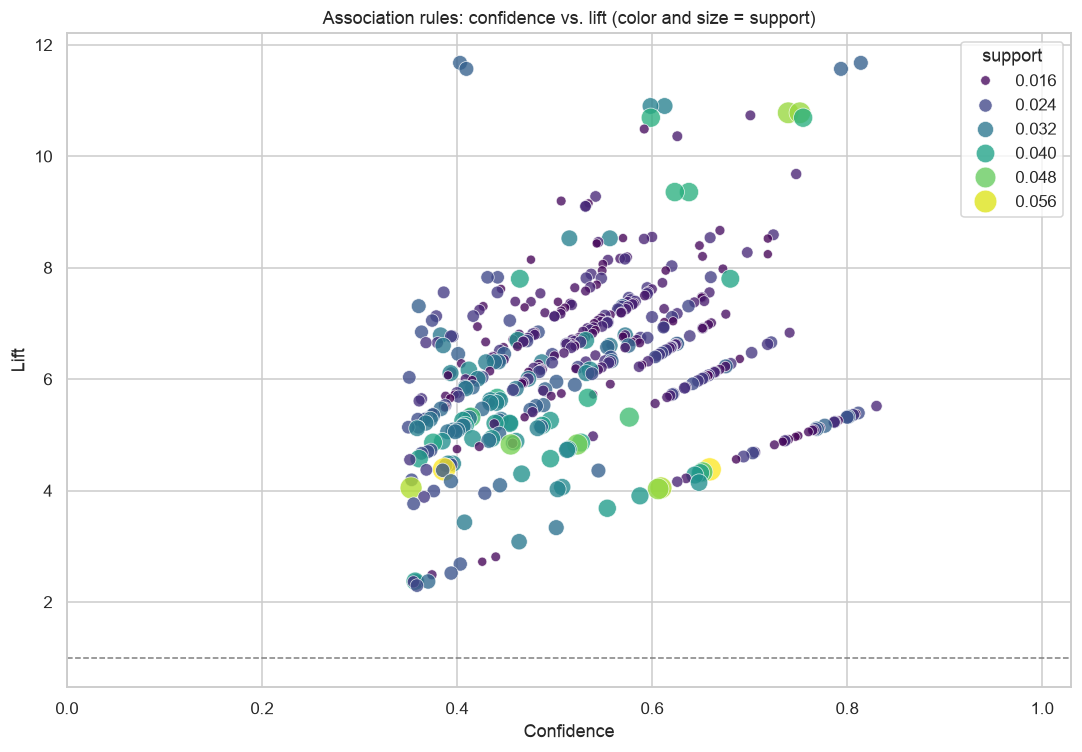

In [42]:
if not apriori_rules.empty:
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        data=apriori_rules,
        x='confidence', y='lift', hue='support', size='support',
        sizes=(35, 230), alpha=0.78, palette='viridis', edgecolor='white'
    )
    plt.axhline(y=1, color='gray', linestyle='--', linewidth=1, label='Lift = 1')
    plt.title('Association rules: confidence vs. lift (color and size = support)')
    plt.xlabel('Confidence')
    plt.ylabel('Lift')
    plt.xlim(0, 1.03)
    save_chart('05_association_rules_scatter.png')
else:
    print('Scatter plot omitted because no rules met the current thresholds.')

### Step 5 — Comparative analysis

We compare **the exact frequent-itemset identities and support values** as a correctness check, then compare **median elapsed wall-clock time**. FP-Growth often avoids candidate explosion and performs well on overlapping baskets, but **the faster algorithm must be determined by the observed results**, not assumed in advance.

Because timing varies with CPU, memory, package versions, and background load, the benchmark describes **this execution environment and this filtered dataset**. It is not a universal speed ranking.

In [43]:
# Compare the support for every common frozenset, not the row order.
apriori_support = apriori_itemsets.set_index('itemsets')['support']
fpgrowth_support = fpgrowth_itemsets.set_index('itemsets')['support']
itemset_keys_a = set(apriori_support.index)
itemset_keys_f = set(fpgrowth_support.index)
common_itemsets = itemset_keys_a & itemset_keys_f
all_itemsets_match = itemset_keys_a == itemset_keys_f
max_support_difference = max(
    (abs(apriori_support[key] - fpgrowth_support[key]) for key in common_itemsets),
    default=0.0
)

comparison = pd.DataFrame({
    'Algorithm': ['Apriori', 'FP-Growth'],
    'Frequent_itemsets': [len(apriori_itemsets), len(fpgrowth_itemsets)],
    'Association_rules': [len(apriori_rules), len(fpgrowth_rules)],
    'Median_seconds': [float(np.median(apriori_times)), float(np.median(fpgrowth_times))],
    'Min_seconds': [min(apriori_times), min(fpgrowth_times)],
    'Max_seconds': [max(apriori_times), max(fpgrowth_times)]
})
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / 'algorithm_comparison.csv', index=False)

print('Identical frequent itemset identities:', all_itemsets_match)
print('Max difference in common itemset support:', f'{max_support_difference:.12g}')
print('Itemsets only Apriori:', len(itemset_keys_a - itemset_keys_f))
print('Itemsets only FP-Growth:', len(itemset_keys_f - itemset_keys_a))

if all_itemsets_match:
    assert np.isclose(max_support_difference, 0, atol=1e-10),         'Both algorithms agree on itemsets but have different support values.'
else:
    print('WARNING: Results differ. Verify both miners use the same input and settings.')

fastest_idx = int(comparison['Median_seconds'].argmin())
slowest_idx = int(comparison['Median_seconds'].argmax())
fastest = comparison.loc[fastest_idx, 'Algorithm']
slowest = comparison.loc[slowest_idx, 'Algorithm']
t_fast = comparison.loc[fastest_idx, 'Median_seconds']
t_slow = comparison.loc[slowest_idx, 'Median_seconds']

print(f'Faster in this run: {fastest} (median {t_fast:.4f}s)')
print(f'Observed speed ratio: {t_slow/t_fast:.2f}x ({slowest} / {fastest})'
      if t_fast > 0 else 'Cannot compute ratio because fastest timing is zero.')

,Algorithm,Frequent_itemsets,Association_rules,Median_seconds,Min_seconds,Max_seconds
0,Apriori,489,451,0.0323,0.0320,0.0329
1,FP-Growth,489,451,0.0403,0.0398,0.0417


Identical frequent itemset identities: True
Max difference in common itemset support: 0
Itemsets only Apriori: 0
Itemsets only FP-Growth: 0
Faster in this run: Apriori (median 0.0323s)
Observed speed ratio: 1.25x (FP-Growth / Apriori)


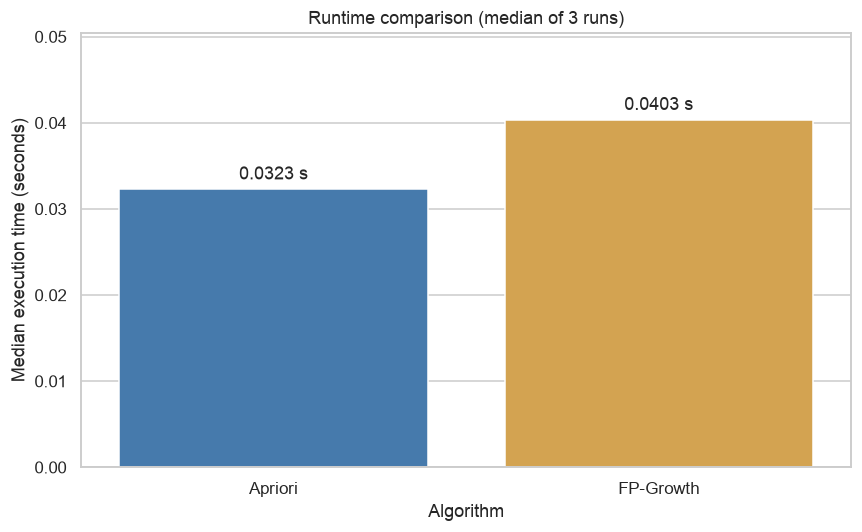

In [44]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=comparison, x='Algorithm', y='Median_seconds',
                 hue='Algorithm', palette=['#357ABD', '#E9A83B'], legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f s', padding=4)
plt.title(f'Runtime comparison (median of {BENCHMARK_REPEATS} runs)')
plt.xlabel('Algorithm')
plt.ylabel('Median execution time (seconds)')
plt.ylim(0, max(comparison['Median_seconds']) * 1.25)
save_chart('06_runtime_comparison.png')

### 5.1 Automated results-based summary

This cell creates a concise comparison using the **measured** values above rather than inventing a winner. Include your own final reflection after reviewing the charts, especially if the runtimes are close.

In [45]:
rule_count = len(apriori_rules)
summary_lines = [
    f'Analysis used {len(basket):,} retained UK invoices and {basket.shape[1]} product columns.',
    f'Minimum support was {MIN_SUPPORT:.1%}; maximum itemset length was {MAX_ITEMSET_LENGTH}.',
    f'Apriori found {len(apriori_itemsets)} itemsets; FP-Growth found {len(fpgrowth_itemsets)}.',
    f'The frequent itemset sets were {"identical" if all_itemsets_match else "not identical"}; '
    f'max common-support difference = {max_support_difference:.2e}.',
    f'Apriori median runtime: {np.median(apriori_times):.4f}s; '
    f'FP-Growth median runtime: {np.median(fpgrowth_times):.4f}s.',
    f'Observed faster algorithm: {fastest} (only for this run and configuration).',
    f'Apriori produced {rule_count} rules with confidence >= {MIN_CONFIDENCE:.0%}; '
    f'{len(apriori_rules[apriori_rules["lift"] >= MIN_LIFT]) if not apriori_rules.empty else 0} '
    f'also met lift >= {MIN_LIFT:.2f}.',
    'Apriori can be expensive when candidate combinations grow; FP-Growth requires tree construction '
    'and its advantage depends on the data distribution.',
    'Challenges included cleaning canceled invoices, representing each basket as Boolean product presence, '
    'and limiting combinatorial growth with transparent sampling and support settings.',
    'Limitations: one geographic market, invoice sampling, top-item filtering, maximum itemset length, '
    'and single-machine benchmark timings. Associations are not causal relationships.'
]

print('\n'.join('- ' + line for line in summary_lines))
(OUTPUT_DIR / 'analysis_summary.txt').write_text('\n'.join(summary_lines) + '\n', encoding='utf-8')

- Analysis used 4,518 retained UK invoices and 65 product columns.
- Minimum support was 1.5%; maximum itemset length was 3.
- Apriori found 489 itemsets; FP-Growth found 489.
- The frequent itemset sets were identical; max common-support difference = 0.00e+00.
- Apriori median runtime: 0.0323s; FP-Growth median runtime: 0.0403s.
- Observed faster algorithm: Apriori (only for this run and configuration).
- Apriori produced 451 rules with confidence >= 35%; 451 also met lift >= 1.20.
- Apriori can be expensive when candidate combinations grow; FP-Growth requires tree construction and its advantage depends on the data distribution.
- Challenges included cleaning canceled invoices, representing each basket as Boolean product presence, and limiting combinatorial growth with transparent sampling and support settings.
- Limitations: one geographic market, invoice sampling, top-item filtering, maximum itemset length, and single-machine benchmark timings. Associations are not causal relationsh

985

### 5.2 Interpretation and practical applications

- **Cross-selling:** Positive-lift rules may suggest products to display together (provided there is enough support).
- **Merchandising:** Repeated co-purchases can inform product placement or promotion bundles.
- **Inventory planning:** Frequently paired products could be reviewed together, but seasonality and stock availability must be investigated separately.
- **Algorithm choice:** Apriori is easy to explain and debug for smaller problems. FP-Growth compresses transactions into a tree and may be preferable as candidate generation becomes expensive. Compare observed runtimes before claiming which is faster here.

**Reflection to personalize after running:** Which actual product pairing did you find most useful? Did the itemset counts agree? Which algorithm ran faster in your environment? Mention one concrete trade-off from the generated figures.

**Ethical/analytical caveat:** The dataset is historical. Item co-occurrence does not demonstrate that one item caused the purchase of another, and conclusions may be affected by invoice sampling and filtering.

### References

1. Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
2. mlxtend documentation — [Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/).
3. mlxtend documentation — [FP-Growth](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/).
4. mlxtend documentation — [Association rules](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/).